<a href="https://colab.research.google.com/github/lathika-sk/yolo26-edge-tracking/blob/main/YOLO26_Edge_Tracking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q -U ultralytics openvino
import ultralytics; ultralytics.checks()

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.3/112.6 GB disk)


In [2]:
from google.colab import files
up = files.upload()
VIDEO = list(up.keys())[0]
print("Uploaded:", VIDEO)

Saving hailuo-03_Realistic_busy_Indian_street_daytime_fixed_camera_wide_shot._Many_pedestrians_wa-0.mp4 to hailuo-03_Realistic_busy_Indian_street_daytime_fixed_camera_wide_shot._Many_pedestrians_wa-0.mp4
Uploaded: hailuo-03_Realistic_busy_Indian_street_daytime_fixed_camera_wide_shot._Many_pedestrians_wa-0.mp4


In [9]:
import cv2, time, subprocess
import numpy as np
from collections import defaultdict, deque
from ultralytics import YOLO
from IPython.display import Video, display

MODEL_PATH = "yolo26n.pt"
CONF, IMGSZ = 0.35, 480
FONT = cv2.FONT_HERSHEY_SIMPLEX

model = YOLO(MODEL_PATH)
names = model.names

def color_for(cls_id):
    """Stable bright color per class."""
    rng = np.random.default_rng(int(cls_id) * 7 + 3)
    return tuple(int(x) for x in rng.integers(80, 255, 3))

cap = cv2.VideoCapture(VIDEO)
assert cap.isOpened(), "Video open aagala. Upload check pannunga."
W, H = int(cap.get(3)), int(cap.get(4))
FPS_IN = cap.get(5) or 24
TOTAL = int(cap.get(7))
writer = cv2.VideoWriter("raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS_IN, (W, H))

trails = defaultdict(lambda: deque(maxlen=30))
seen = defaultdict(set)
lat = []
frame_no = 0

try:
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame_no += 1

        t0 = time.perf_counter()
        res = model.track(frame, persist=True, tracker="bytetrack.yaml",
                          conf=CONF, imgsz=IMGSZ, device="cpu", verbose=False)[0]
        ms = (time.perf_counter() - t0) * 1000
        lat.append(ms)

        now = 0
        boxes = res.boxes
        if boxes is not None and len(boxes):
            xyxy = boxes.xyxy.cpu().numpy().astype(int)
            cls = boxes.cls.cpu().numpy().astype(int)
            confs = boxes.conf.cpu().numpy()
            ids = boxes.id.cpu().numpy().astype(int) if boxes.id is not None else [None] * len(cls)
            now = len(cls)

            for (x1, y1, x2, y2), c, p, i in zip(xyxy, cls, confs, ids):
                col, name = color_for(c), names[int(c)]
                cv2.rectangle(frame, (x1, y1), (x2, y2), col, 2)

                label = f"#{int(i)} {name} {p:.2f}" if i is not None else f"{name} {p:.2f}"
                (tw, th), _ = cv2.getTextSize(label, FONT, 0.5, 1)
                cv2.rectangle(frame, (x1, max(y1 - th - 8, 0)), (x1 + tw + 6, y1), col, -1)
                cv2.putText(frame, label, (x1 + 3, max(y1 - 4, th)), FONT, 0.5, (0, 0, 0), 1, cv2.LINE_AA)

                if i is not None:
                    i = int(i)
                    seen[name].add(i)
                    trails[i].append(((x1 + x2) // 2, y2))
                    if len(trails[i]) > 1:
                        pts = np.array(trails[i], np.int32).reshape(-1, 1, 2)
                        cv2.polylines(frame, [pts], False, col, 2, cv2.LINE_AA)


        top = sorted(seen.items(), key=lambda kv: -len(kv[1]))[:6]
        lines = ["YOLO26n | NMS-free + ByteTrack",
                 f"FPS: {1000 / ms:.1f}  ({ms:.0f} ms)",
                 f"Frame {frame_no}/{TOTAL}",
                 f"Objects in frame: {now}"] + [f"{k}: {len(v)} unique" for k, v in top]
        ph = 14 + 24 * len(lines)
        overlay = frame.copy()
        cv2.rectangle(overlay, (8, 8), (330, 8 + ph), (0, 0, 0), -1)
        frame = cv2.addWeighted(overlay, 0.55, frame, 0.45, 0)
        for k, line in enumerate(lines):
            colr = (0, 255, 255) if k == 0 else (255, 255, 255)
            cv2.putText(frame, line, (16, 32 + 24 * k), FONT, 0.55, colr, 1, cv2.LINE_AA)

        writer.write(frame)
finally:
    cap.release()
    writer.release()

subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", "raw.mp4",
                "-vcodec", "libx264", "-pix_fmt", "yuv420p", "output_tracked.mp4"], check=True)

print(f"\nFrames: {frame_no} | Avg latency: {np.mean(lat):.1f} ms | Avg FPS: {1000/np.mean(lat):.1f}")
print("Unique objects tracked:")
for k, v in sorted(seen.items(), key=lambda kv: -len(kv[1])):
    print(f"  {k:<15}{len(v)}")
display(Video("output_tracked.mp4", embed=True, width=800))


Frames: 158 | Avg latency: 54.8 ms | Avg FPS: 18.2
Unique objects tracked:
  person         33
  motorcycle     16
  car            12
  bus            5
  traffic light  3
  umbrella       3
  bicycle        3
  dog            2
  backpack       2
  truck          2
  cow            1
  handbag        1


Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs

PyTorch: starting from 'yolo26n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (5.3 MB)

OpenVINO: starting export with openvino 2026.4.1-22982-e213a147257-releases/2026/4...


/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


OpenVINO: export success ✅ 2.6s, saved as 'yolo26n_openvino_model/' (9.6 MB)

Export complete (3.0s)
Results saved to /content/yolo26n_openvino_model
Predict:         yolo predict task=detect model=yolo26n_openvino_model/ imgsz=640 
Validate:        yolo val task=detect model=yolo26n_openvino_model/ imgsz=640  
Visualize:       https://netron.app
Loading yolo26n_openvino_model/ for OpenVINO inference...
Using OpenVINO LATENCY mode for batch=1 inference on CPU...

Model                    Avg ms   P95 ms     FPS
------------------------------------------------
YOLO11n PyTorch            82.1    110.1    12.2
YOLO26n PyTorch            65.9     75.4    15.2
YOLO26n OpenVINO          102.0    128.1     9.8

YOLO26n OpenVINO vs YOLO11n PyTorch: -24.3% faster


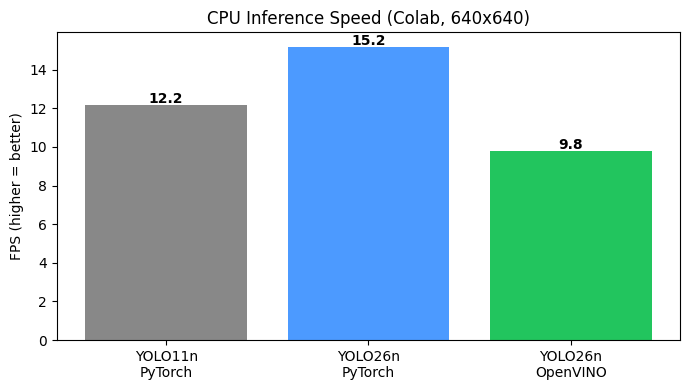

In [10]:
import time, cv2, numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

cap = cv2.VideoCapture(VIDEO); ok, img = cap.read(); cap.release()
assert ok, "Frame read aagala"

def bench(m, runs=50, warmup=5):
    for _ in range(warmup):
        m.predict(img, imgsz=640, device="cpu", verbose=False)
    t = []
    for _ in range(runs):
        s = time.perf_counter()
        m.predict(img, imgsz=640, device="cpu", verbose=False)
        t.append((time.perf_counter() - s) * 1000)
    return float(np.mean(t)), float(np.percentile(t, 95))

results = {}
results["YOLO11n\nPyTorch"] = bench(YOLO("yolo11n.pt"))
results["YOLO26n\nPyTorch"] = bench(YOLO("yolo26n.pt"))

ov_path = YOLO("yolo26n.pt").export(format="openvino")       # edge export
results["YOLO26n\nOpenVINO"] = bench(YOLO(ov_path, task="detect"))

print(f"\n{'Model':<22}{'Avg ms':>9}{'P95 ms':>9}{'FPS':>8}")
print("-" * 48)
for k, (avg, p95) in results.items():
    print(f"{k.replace(chr(10), ' '):<22}{avg:>9.1f}{p95:>9.1f}{1000/avg:>8.1f}")

base = list(results.values())[0][0]
best = list(results.values())[-1][0]
print(f"\nYOLO26n OpenVINO vs YOLO11n PyTorch: {(base - best) / base * 100:.1f}% faster")

labels = list(results.keys()); fps = [1000 / v[0] for v in results.values()]
plt.figure(figsize=(7, 4))
bars = plt.bar(labels, fps, color=["#888", "#4C9AFF", "#22C55E"])
for b, f in zip(bars, fps):
    plt.text(b.get_x() + b.get_width() / 2, f + 0.1, f"{f:.1f}", ha="center", fontweight="bold")
plt.ylabel("FPS (higher = better)"); plt.title("CPU Inference Speed (Colab, 640x640)")
plt.tight_layout(); plt.savefig("benchmark.png", dpi=150); plt.show()

In [11]:
from google.colab import files
files.download("output_tracked.mp4")
files.download("benchmark.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>